# 01 Data exploration (EuroSAT multispectral)

This notebook describes the data and checks it before any split or model.
It covers rubric criterion 3, "Data": "description (size, type, classes, distribution); exploratory analysis" (Group_Project_Guidelines_and_Rubric.pdf, marking scheme, row 3).

Reusable functions live in `src/piece_of_crop/data.py` and are imported here, following the course pattern: "Notebooks are for exploration, explanation and results. Reusable logic should be placed in src/." (IE_Packaging_and_Assignment_Preparation_Content_Draft.pdf, slide 15).

Every figure is saved in `results/figures/` with a title, axis labels and a meaningful file name (packaging deck, slide 17).

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from piece_of_crop import (
    BAND_NAMES,
    CLASS_NAMES,
    find_duplicates,
    list_files,
    read_bands,
    summarise_files,
    to_rgb_image,
)

project_root = Path.cwd().parents[0]
data_dir = project_root / "data" / "EuroSAT_MS"
figures_dir = project_root / "results" / "figures"
figures_dir.mkdir(parents=True, exist_ok=True)

## 1. Files and classes

We first inspect the folder structure, the classes and the image sizes, as the course CNN notebook does before any model ("Inspect the folder structure, classes and image sizes", CNN_Class_Competition_2_Food_Classification_Explained.pdf, assignment requirements, step 2).

In [2]:
files = list_files(data_dir)
print("Number of files:", len(files))

class_counts = files["class_name"].value_counts().reindex(CLASS_NAMES)
class_table = pd.DataFrame({"images": class_counts, "share": (class_counts / len(files)).round(3)})
class_table

Number of files: 27000


,images,share
class_name,,
AnnualCrop,3000,0.111
Forest,3000,0.111
HerbaceousVegetation,3000,0.111
Highway,2500,0.093
Industrial,2500,0.093
Pasture,2000,0.074
PermanentCrop,2500,0.093
Residential,3000,0.111
River,2500,0.093


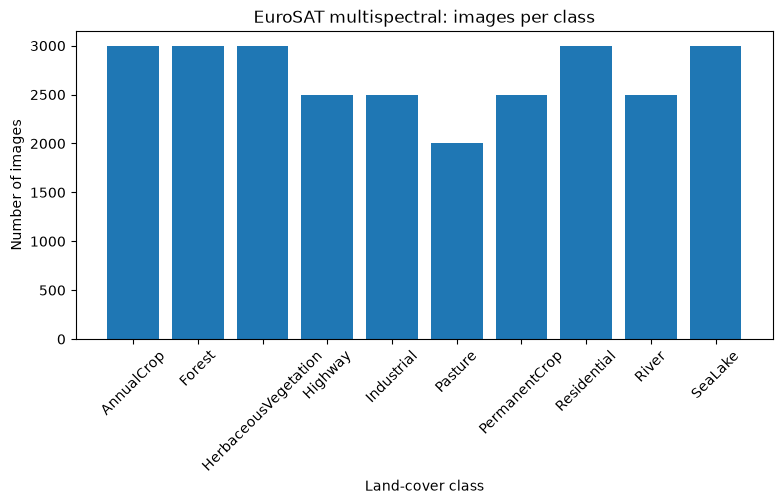

In [3]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(class_table.index, class_table["images"])
ax.set_title("EuroSAT multispectral: images per class")
ax.set_xlabel("Land-cover class")
ax.set_ylabel("Number of images")
ax.tick_params(axis="x", rotation=45)
plt.savefig(figures_dir / "class_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

**Claim.** The classes are mildly imbalanced, and the smallest class, Pasture, is one of the classes that matter most to a crop insurer.

**Reasons.** Pasture has 2,000 images and the largest classes have 3,000, so Pasture has two thirds of their examples. A model sees fewer Pasture patches during training and can learn it less well.

**Evidence.** The table above (Pasture 2,000; AnnualCrop, Forest, HerbaceousVegetation, Residential and SeaLake 3,000 each). The proposal names pasture versus annual crop as an example of a costly confusion.

**Warrant.** Overall accuracy weights each class by its size, so weaker results on a small class are hidden. Precision and recall per class, and the F1-score, show them (lecture_2_introduction_to_ML.pdf, slides 34 and 35). That is why we report macro-F1 and per-class recall next to accuracy.

**Counterargument.** A ratio of 1.5 is small, and many models handle it without any correction. We accept this: we do not resample or reweight the classes, and only make sure the metrics would reveal a problem if there is one.

## 2. Corrupt files, duplicates and summary per file

Reading 27,000 GeoTIFFs takes a few minutes, so every file is read once here and its facts are saved to `results/file_summary.csv`: whether it can be read, a fingerprint of its pixels, its location and, for each band, the mean, standard deviation, minimum and maximum.

In [4]:
summary = summarise_files(files)
summary.to_csv(project_root / "results" / "file_summary.csv", index=False)

print(summary["status"].value_counts())

status
ok    27000
Name: count, dtype: int64


In [5]:
duplicates = find_duplicates(summary)
print("Files whose pixels are identical to another file:", len(duplicates))
duplicates[["file", "class_name", "fingerprint"]]

Files whose pixels are identical to another file: 0


,file,class_name,fingerprint


**Claim.** All 27,000 files are usable and none is an exact duplicate of another, so nothing is removed before the split.

**Reasons.** Every file could be opened, had 13 bands of 64 x 64 pixels, contained only finite values and was not all zeros. No two files share the same pixel fingerprint.

**Evidence.** The status count shows 27,000 files marked "ok". The duplicate check finds 0 files. The proposal promised both checks ("Check for corrupt files", proposal, section 1 "Data preprocessing").

**Warrant.** A file should only be removed if it cannot be used, or if an exact copy could end up in both training and test data and inflate the test score. Neither case occurs, so the dataset stays complete.

**Counterargument.** An exact-duplicate check cannot see near-duplicates: neighbouring patches cut from the same satellite scene look alike but differ in their pixels. We accept this limit of the check. The spatial split in notebook 02 is our answer to that risk, because the test set must behave like "new" data that was never used in training (lecture_2_introduction_to_ML.pdf, slide 24).

## 3. Band order

The models, the RGB input and the haze test all depend on knowing which band is which. Sources disagree about where band B8A (narrow near-infrared, 865 nm) sits in the EuroSAT files: some list it as the 9th band, others as the last. We check it in the data instead of trusting a list.

Band B10 (1,375 nm) is a cirrus band: ESA added it to detect cirrus clouds (ESA, Sentinel-2 mission page "Heritage", external), and it is the band that "does not see the ground" (ESA, Sentinel-2 MSI technical guide "MSI Instrument", external). Its values should therefore be far below those of every other band. The table shows which position has them.

In [6]:
band_means = pd.DataFrame({
    "band": BAND_NAMES,
    "mean over all files": [summary[f"mean_{band}"].mean() for band in BAND_NAMES],
})
band_means.round(1)

,band,mean over all files
0,B01,1353.699951
1,B02,1117.199951
2,B03,1041.900024
3,B04,946.599976
4,B05,1199.199951
5,B06,2003.000000
6,B07,2374.000000
7,B08,2301.199951
8,B09,732.200012
9,B10,12.100000


**Claim.** In the EuroSAT_MS files band B8A is stored last (position 13), so `BAND_NAMES` in `data.py` is B01 to B12 followed by B8A.

**Reasons.** Position 10 has a mean of 12.1, far below every other position (the next lowest is 732.2 at position 9). Only B10, which does not see the ground, can produce such values. Position 13 has a mean of 2,599.8, close to B08 (2,301.2) at position 8, which fits a second near-infrared band.

**Evidence.** The table above, computed over all 27,000 files. ESA describes B10 as the band that "does not see the ground" (Sentinel-2 MSI technical guide, external).

**Warrant.** If B8A were the 9th band, B10 would sit at position 11, and position 11 would show values near zero. Position 11 shows 1,820.7 instead. The only order that puts the near-zero band at position 10 is the one with B8A last.

**Counterargument.** This order is inferred from the values, not read from labels in the file. We accept that the evidence is indirect, but two independent clues agree: the near-zero cirrus band and the near-infrared values at the last position. The RGB input does not depend on this at all, because bands 4, 3 and 2 sit at positions 4, 3 and 2 in either order.

## 4. One example per class

The images are shown in true colour from bands 4, 3 and 2. Each band is stretched separately between its own 2nd and 98th percentile, only for display, so that no single band dominates the colour. The models get the raw bands.

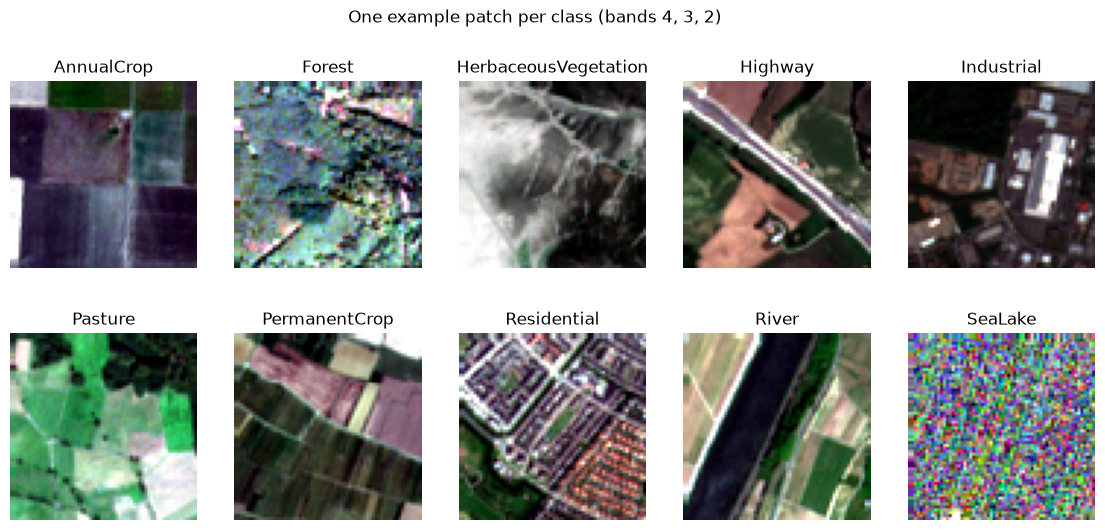

In [7]:
fig,axes =plt.subplots(2, 5, figsize=(14, 6))
for ax,class_name in zip(axes.flat, CLASS_NAMES):
    path =files.loc[files["class_name"] == class_name, "path"].iloc[0]
    ax.imshow(to_rgb_image(read_bands(path)))
    ax.set_title(class_name)
    ax.axis("off")

plt.suptitle("One example patch per class (bands 4, 3, 2)")
plt.savefig(figures_dir /"example_per_class.png", dpi=150, bbox_inches="tight")
plt.show()

## 5. Value range per band

Normalisation (notebook 02) has to fit the values the bands really take, so we look at them first.

In [8]:
# value range for every band over all the files
smallest = []
median_means= []
p99_max = []
largest =[]
for band in BAND_NAMES:
    smallest.append(summary[f"min_{band}"].min())
    median_means.append( summary[f"mean_{band}"].median() )
    p99_max.append(summary[f"max_{band}"].quantile(0.99))
    largest.append(summary[f"max_{band}"].max( ))

# put it togheter in 1 table
value_ranges = pd.DataFrame({"band": BAND_NAMES,
    "smallest value":smallest,
    "median of file means": median_means,
    "99th percentile of file maxima" : p99_max,
    "largest value": largest})
#print(value_ranges.shape)
value_ranges.round(1)

,band,smallest value,median of file means,99th percentile of file maxima,largest value
0,B01,808.0,1322.400024,2952.0,17720.0
1,B02,0.0,1086.099976,7558.4,28000.0
2,B03,0.0,1001.200012,8102.1,28000.0
3,B04,0.0,861.400024,9789.4,28000.0
4,B05,174.0,1168.900024,5371.0,24008.0
5,B06,153.0,2108.800049,5743.0,27791.0
6,B07,128.0,2477.800049,6338.0,28001.0
7,B08,0.0,2407.800049,10316.1,28003.0
8,B09,40.0,716.400024,2221.0,15384.0
9,B10,1.0,11.500000,38.0,183.0


**Claim.** Every band has a few extreme values far above its usual range, so notebook 02 must check whether to clip the values before scaling them.

**Reasons.** The largest values reach about 28,000 in B02, B03, B04, B07, B08 and B8A, while 99% of the patch maxima stay below 10,316 (B08) and 9,789 (B04). Some bands also contain the value 0, far below their medians.

**Evidence.** The table above. The maxima of 28,000 to 28,003 repeat across several bands, which suggests a cap rather than ordinary light. Zeros appear in B02, B03, B04 and B08.

**Warrant.** The mean and standard deviation used to scale each band are pulled by a few extreme values, and the course asks us to "explain your normalization choice" (CNN_Class_Competition_2_Food_Classification_Explained.pdf, assignment requirements, step 5). A choice that ignores these ranges could not be explained.

**Counterargument.** The extreme values are rare and may be real (bright roofs, clouds or snow), so clipping them throws away true information. We do not decide here. Notebook 02 counts how many pixels lie beyond a high percentile, using the training split only, and decides from that.

## 6. Average spectrum per class

This plot is the first evidence for the research question. If two classes look alike in red, green and blue but differ in the other bands, the extra bands carry information that RGB lacks.

Each line is the class average of the patch means. The shaded band is plus and minus one standard deviation across the patches of that class, so overlap between classes stays visible: different averages alone would not show that the classes can be told apart. The bands are drawn in wavelength order, which is not the order they have in the files.

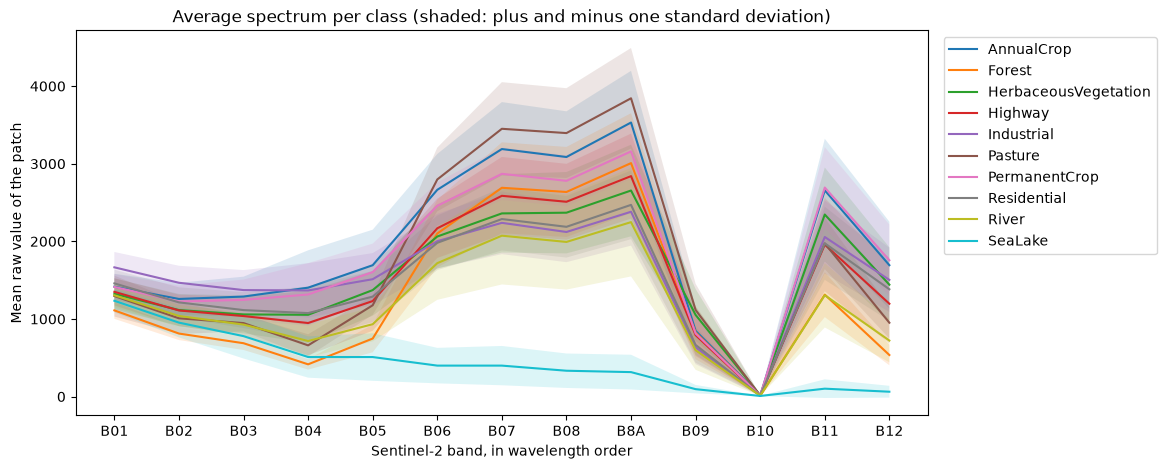

In [9]:
wavelength_order = ["B01", "B02", "B03", "B04", "B05", "B06", "B07","B08", "B8A","B09","B10","B11", "B12" ]

mean_columns = [f"mean_{band}" for band in wavelength_order]

fig, ax = plt.subplots(figsize=(11, 5))
x = np.arange(len(wavelength_order))
for class_name in CLASS_NAMES:
    class_rows = summary.loc[summary["class_name"] == class_name, mean_columns]
    average = class_rows.mean().to_numpy()
    spread = class_rows.std().to_numpy()
    ax.plot(x, average, label=class_name)
    ax.fill_between(x, average - spread, average + spread, alpha=0.15)

ax.set_xticks(x)
ax.set_xticklabels(wavelength_order)
ax.set_title("Average spectrum per class (shaded: plus and minus one standard deviation)")
ax.set_xlabel("Sentinel-2 band, in wavelength order")
ax.set_ylabel("Mean raw value of the patch")
ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left")
plt.savefig(figures_dir / "spectrum_per_class.png", dpi=150, bbox_inches="tight")
plt.show()

**Claim.** The classes that matter most to an insurer overlap most in the visible bands and separate more in the red-edge, near-infrared and short-wave infrared bands. This is where a 13-band advantage, if any, should come from.

**Reasons.** In B02 to B04 (blue, green, red) AnnualCrop, PermanentCrop, HerbaceousVegetation and Pasture lie close together and their shaded bands overlap. From B06 to B8A the vegetation classes spread apart: at B8A Pasture is near 3,850, AnnualCrop near 3,550, PermanentCrop near 3,150 and HerbaceousVegetation near 2,650. In B12, Pasture (about 950) lies well below AnnualCrop (about 1,700), and this is the pair the proposal names as a costly confusion.

**Evidence.** The figure above, saved as `results/figures/spectrum_per_class.png`.

**Warrant.** A classifier can only separate two classes on bands where their values differ. Where the shaded bands overlap less, fewer patches of the two classes look alike. A convolution sums over all input channels (lecture_8_DL_for_CV_1_compressed.pdf, slide 32), so a CNN given 13 channels can use these bands directly.

**Counterargument.** These are averages of patch means. The shaded bands of Pasture and AnnualCrop still overlap in the near-infrared, so many single patches remain alike. CNNs also use shapes and textures, which RGB contains. The plot therefore suggests where the extra bands could help but proves nothing: the models in notebooks 03 to 05 decide. B10 is close to zero for every class and carries almost no information.

## 7. Where the patches are

Each GeoTIFF carries its map position. We plot the centre of every patch to see where the data comes from and whether patches cluster, which matters for the split in notebook 02.

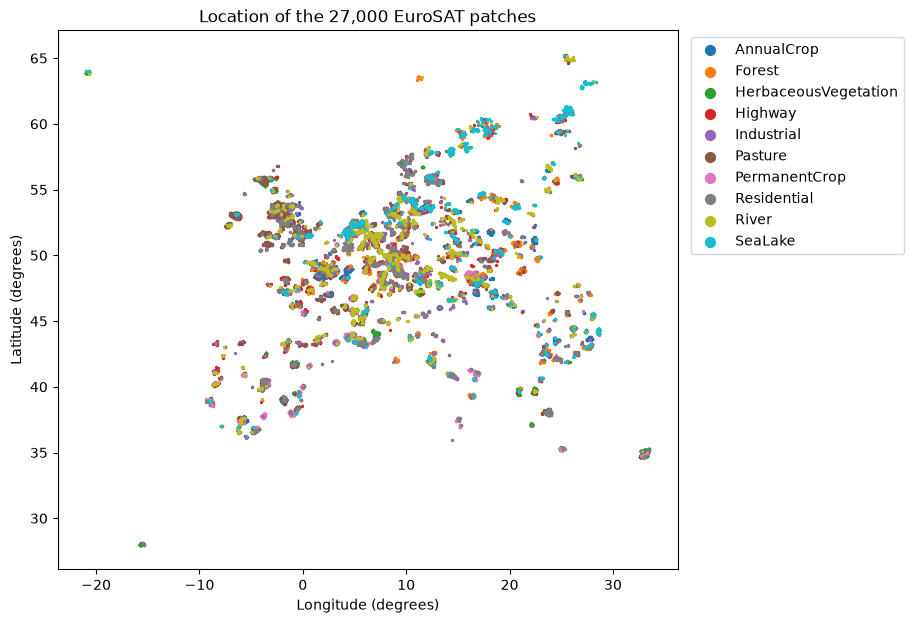

In [10]:
# map of where all the patches are
fig,ax = plt.subplots(figsize=(8,7))

for class_name in CLASS_NAMES:
    class_rows = summary[summary["class_name"]==class_name]
    #print(class_name, len(class_rows))
    ax.scatter(class_rows["lon"], class_rows["lat"],s=2, label = class_name)
ax.set_title("Location of the 27,000 EuroSAT patches")
ax.set_xlabel("Longitude (degrees)")
ax.set_ylabel( "Latitude (degrees)")
ax.legend(markerscale=5,bbox_to_anchor=(1.01, 1), loc="upper left")  # legend outside so it dosent cover the points
plt.savefig(figures_dir/"patch_locations.png", dpi=150, bbox_inches="tight")
plt.show()

**Claim.** The patches come in tight geographic clusters and some classes are concentrated in certain regions, so a random split would place near-identical neighbours in both training and test data. The data also covers Europe only.

**Reasons.** Patches cut from the same satellite scene share the place, the date and the atmosphere. If some go to training and others to test, the test score partly measures how well the model remembers that scene.

**Evidence.** The map above (`results/figures/patch_locations.png`): the points form small dense clusters instead of spreading evenly. Pasture (brown) is concentrated around Ireland and Great Britain. All patches lie between about 21 degrees west and 33 degrees east, and 28 and 65 degrees north.

**Warrant.** The test set must be "new" data that was never used during training (lecture_2_introduction_to_ML.pdf, slide 24). Neighbours from one cluster in both sets break that rule. A regional class like Pasture also lets a model learn where a patch comes from instead of what covers it.

**Counterargument.** A spatial split makes the test harder and the class proportions per split less even, and published EuroSAT results use random splits, so our scores will not be comparable to them. We accept this: an honest estimate for new parcels matters more to an insurer than a comparable number. Coverage limited to Europe is a limitation for the Responsible AI section, since a model can "reflect and amplify our biases" (17877564097133bHYk_202907.pptx, slide 44).

## Summary

- 27,000 usable files in 10 classes, mildly imbalanced. Pasture, an insurer-critical class, is the smallest (2,000).
- No corrupt files and no exact duplicates, so nothing is removed.
- B8A is the last band in the files. `data.py` uses this order.
- Each band has rare extreme values (up to about 28,000) and some zeros, so clipping is checked in notebook 02.
- Insurer-relevant classes overlap in RGB and separate more in red-edge, near-infrared and SWIR bands.
- Patches are clustered in space and some classes are regional, so notebook 02 uses a spatial split. The data covers Europe only.